## MATH3603 Deep Learning & Explainable AI ─ Assignment 1


<div class="logos"><img src="MATH3603_logo.jpg" width="125px" align="right"></div>

This assignment is designed to test your basic understanding of artificial neural networks. The task consists of two parts with practical questions for you to answer using Python: 
> **Part A.** Define and implement the basic elements of a neural network [**40 marks**]<br>
> **Part B.** Carry out image classification using a Multilayer Perceptron (MLP) [**60 marks**]

The maximum number of marks for each part is shown above, with a total of **100 marks** available. Partial marks for individual tasks are shown below in the section headings.

**This is a summative assessment contributing 30% to the final module grade.**

### Objectives 

Through this assignment you will:

> - Demonstrate understanding of the design and essential ingredients of a simple neural network.
> - Design and build your first deep neural network (DNN). 
> - Train a DNN model for image classification of natural scene data.  
> - Use various metrics to ascertain how your DNN model is performing. 


### Setup and resources 

> - You must work using the template notebook provided with the task. 
> - Please **do not remove anything in the template**. You are allowed to add new code cells.
> - You should implement this assignment using **Python** and **PyTorch**.

Having a GPU will speed up the training process. See the document "Computing Information Sheet" on Minerva about setting up a working environment and various ways to access a GPU.

#### Required packages

Please make sure that you have the following basic packages installed before you begin:
> - [numpy](https://www.numpy.org) is a package for scientific computing with Python
> - [h5py](https://www.h5py.org) is a package to interact with compactly stored datasets
> - [matplotlib](https://matplotlib.org) can be used for plotting graphs in Python
> - [PyTorch](https://pytorch.org/docs/stable/index.html) is a library widely used for building deep-learning frameworks

If needed, you can install these and other packages using [pip](https://pypi.org/project/opencv-python/) or [conda](https://anaconda.org/conda-forge/opencv).

Importing some other packages may be required; hints are provided for you in the template below.


### Submission

#### Due date
The assignment is released on Minerva on Friday 9th October 2026 and is due for submission via Gradescope **by 09:00 on Monday 2nd November 2026**. 

If you submit your work past the deadline, penalties will be applied: for every period of 24 hours or part thereof that your assessment is overdue, you will lose 5% of the total marks available for that assessment component. This includes weekends, Bank Holidays and University closed days. 

If you are unable to submit your work on time, please consider applying for an extension or exemption due to mitigating circumstances.

#### What to submit

Please submit a single `*.zip` file through **Minerva Gradebook Submission**, comprising the following files:

> 1. Your completed Jupyter notebook as `*.ipynb` file.
> 2. The `*.html` version of your notebook (saved using **File > Save and Export Notebook As > HTML**).
> 3. Academic integrity statement (signed and dated) including the Gen AI use disclosure.

#### Further guidance

> - In each section, put the relevant code containing your solution.
> - When defining a function, please add a description of the arguments, along with their dimensions (shapes).
> - Please annotate your code as appropriate to make it more readable for humans and to explain your chain of thought.
> - You may re-use functions you defined previously, but any new code must be in the relevant section.
> - Feel free to add as many code cells as you need under each section.
> - Before submission, check that all Python cells have been run.
> - Make sure that all outputs (including all graphs you would like to be marked) are displayed in the `*.html` file that you will submit for marking.

#### Your details

Your full name: 

--> double click to respond

Your student username (e.g. `mm24jb`): 

--> double click to respond

## Part A: Design and Ingredients of a Neural Network [40 marks]

### Tasks

> **A1.** Define the sigmoid activation function and plot its graph [10 marks] <br>
> **A2.** Implement forward pass including weights [10 marks] <br>
> **A3.** Define and evaluate the cost value [10 marks] <br>
> **A4.** Implement backward pass and update the weights [10 marks]

To answer these questions, please provide the required Python code in the code cells below and run it on a specific DNN example shown below:

<div class="figure"><img src="Assessment_1_figure.jpg" width="620px" align="center"></div>

<br>

This figure represents a two-layer neural network (with sigmoid activation functions) for classification of 2D input vectors $\begin{bmatrix}x_1\\x_2\end{bmatrix}$ into 2 x 2 = 4 classes  labelled $\begin{bmatrix}0\\0\end{bmatrix}$, $\begin{bmatrix}1\\0\end{bmatrix}$, $\begin{bmatrix}0\\1\end{bmatrix}$, and $\begin{bmatrix}1\\1\end{bmatrix}$. The input values, as well as the associated weights and biases in each layer, are shown in the figure. The neurons in the output layer produce their scalar predictions independently, with the corresponding ground truth `0/1` shown on the right. 

<br>

**Notation:**
> $x$ -- training instance (input) <br>
> $y_{\text{true}}$ -- ground truth <br>
> $z$ -- affine transformation of $x$ <br>
> $w$ -- weight <br>
> $b$ -- bias <br>
> $a$ -- activation through sigmoid

In [4]:
%pip install numpy
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [5]:
import numpy as np

### A1. Activation function [10 marks]

The sigmoid squashes any real number into the interval $(0,1)$:

$$\sigma(x)=\frac{1}{1+e^{-x}}$$

It is smooth and differentiable everywhere, with $\sigma'(x)=\sigma(x)\,(1-\sigma(x))$ — this nice form is what makes the backward pass in A4 cheap to compute. Its output can be read as a probability, which is why it suits the 0/1 outputs of this network.

#### A1.1. Define the sigmoid activation function

In [6]:
# Your code here:
def sigmoid(x):
    """
    Applies sigmoid function to scalar
    or n-dimensional array x
    """
    return 1 / (1 + np.exp(-x))
    

`np.exp` works element-wise on arrays, so the same function handles a single number, a vector $z$ of one layer, or a whole batch.

#### A1.2. Print `sigmoid(-0.2) = <value>` with 4 decimal places

In [7]:
# Your code here:
print(f"sigmoid(-0.2) = {round(sigmoid(-0.2), 4)}")

sigmoid(-0.2) = 0.4502


#### A1.3. Plot the graph of `y = sigmoid(x)`

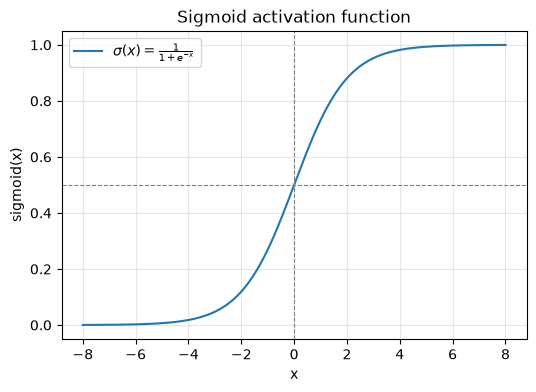

In [8]:
import matplotlib.pyplot as plt

x = np.linspace(-8, 8, 400)     # dense grid so the curve looks smooth
y = sigmoid(x)

plt.figure(figsize=(6, 4))
plt.plot(x, y, label=r"$\sigma(x)=\frac{1}{1+e^{-x}}$")
plt.axhline(0.5, color="grey", ls="--", lw=0.8)   # sigma(0) = 0.5
plt.axvline(0, color="grey", ls="--", lw=0.8)
plt.xlabel("x")
plt.ylabel("sigmoid(x)")
plt.title("Sigmoid activation function")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

The curve is S-shaped, passes through $(0, 0.5)$, tends to 0 as $x\to-\infty$ and to 1 as $x\to+\infty$. It is steepest at $x=0$ (gradient $0.25$) and flattens at the extremes, where gradients become very small (the *vanishing-gradient* problem).

### A2. Forward propagation [10 marks]

**Conventions used** (layer $l=1$ is the hidden layer, $l=2$ the output layer):

- $W^{[l]}$ has shape (neurons in layer $l$, neurons in layer $l-1$), so $W^{[l]}_{ij}$ is the weight from neuron $j$ of the previous layer into neuron $i$ of layer $l$.
- Affine step: $z^{[l]} = W^{[l]}a^{[l-1]} + b^{[l]}$, with $a^{[0]}=x$.
- Activation: $a^{[l]}=\sigma(z^{[l]})$.

#### A2.1. Define forward pass 

In [9]:
def forward_pass(W, b, X):
    """
    Forward propagation through a fully connected network with sigmoid activations.

    Arguments:
    W -- list of weight matrices, W[l] has shape (n_out_l, n_in_l)
         (here: W[0] is (2, 2) hidden layer, W[1] is (2, 2) output layer)
    b -- list of bias vectors, b[l] has shape (n_out_l,)   (here: (2,) each)
    X -- input vector, shape (n_in,)                       (here: (2,))

    Return:
    Z -- list of affine outputs z^[l] = W^[l] a^[l-1] + b^[l], one (n_out_l,) array per layer
    A -- list of activations a^[l] = sigmoid(z^[l]),           one (n_out_l,) array per layer
         (A[-1] is the network's prediction)
    """
    Z, A = [], []
    a_prev = X                          # a^[0] = x
    for W_l, b_l in zip(W, b):
        z = W_l @ a_prev + b_l          # Forward propagation (affine transform)
        a = sigmoid(z)                  # Activation
        Z.append(z)
        A.append(a)
        a_prev = a                      # output of this layer is input of the next
    return Z, A

The loop applies the same two operations to every layer. The key point is that the **activation $a^{[1]}$ of the hidden layer (not its raw $z^{[1]}$) is fed into the output layer**. All $z$ and $a$ values are stored, because the backward pass in A4 needs them.

#### A2.2. Find forward pass for the hidden layer

In [10]:
# Your code here:
# Input and parameters taken from the figure
X = np.array([0.1, 0.5])                       # x1, x2

W = [np.array([[0.1, 0.3],                     # hidden layer  W^[1], shape (2, 2)
               [0.2, 0.4]]),
     np.array([[0.5, 0.6],                     # output layer  W^[2], shape (2, 2)
               [0.7, 0.8]])]
b = [np.array([0.25, 0.25]),                   # hidden biases b^[1]
     np.array([0.35, 0.35])]                   # output biases b^[2]

Z, A = forward_pass(W, b, X)

print("Hidden layer  z^[1] =", Z[0])
print("Hidden layer  a^[1] =", A[0])

Hidden layer  z^[1] = [0.41 0.47]
Hidden layer  a^[1] = [0.60108788 0.61538376]


In [11]:
# Optional: manual check

print(W[0])

# z_11 = w_11*x1 + w_12*x2 + b_1 ,  z_12 = w_21*x1 + w_22*x2 + b_2
Z_11 = W[0][0, 0] * X[0] + W[0][0, 1] * X[1] + b[0][0]
Z_12 = W[0][1, 0] * X[0] + W[0][1, 1] * X[1] + b[0][1]

print(Z_11)
print(Z_12)
print(sigmoid(Z_11), sigmoid(Z_12))

[[0.1 0.3]
 [0.2 0.4]]
0.41000000000000003
0.47000000000000003
0.6010878788483698 0.6153837563911821


#### A2.3. Find the prediction values from the output layer

In [12]:
# Your code here:
print("Output layer  z^[2] =", Z[1])
print("Output layer  a^[2] (predictions) =", A[1])
print(f"y_pred_1 = {A[1][0]:.4f},  y_pred_2 = {A[1][1]:.4f}")

Output layer  z^[2] = [1.01977419 1.26306852]
Output layer  a^[2] (predictions) = [0.73492861 0.77955388]
y_pred_1 = 0.7349,  y_pred_2 = 0.7796


The two output neurons each give a probability that their label is 1. These are the predictions $\hat y_1,\hat y_2$ compared with the ground truth in A3.

### A3. Cost value [10 marks]

#### A3.1. Define the cost using negative log-liklihood loss (binary cross entropy)

Each output neuron is an independent binary classifier, so for output $k$ with ground truth $y_k\in\{0,1\}$ and prediction $\hat y_k$ the negative log-likelihood is

$$\ell_k=-\big[y_k\ln \hat y_k+(1-y_k)\ln(1-\hat y_k)\big]$$

i.e. $-\ln$ of the probability the network assigned to the *correct* label. The cost is the mean over the $N=2$ outputs: $J=\frac1N\sum_k \ell_k$.

In [13]:
def cost(Y_out, Y_true):
    """
    Binary cross entropy (negative log-likelihood), averaged over the output neurons.

    Arguments:
    Y_out  -- predicted probabilities of label 1 (output of the sigmoid), shape (N,)   (here N = 2)
    Y_true -- ground-truth labels, each 0 or 1,                          shape (N,)

    Return:
    J -- scalar cost
    """
    # probability the network gave to the true label: y_hat if y = 1, (1 - y_hat) if y = 0
    p_true = Y_true * Y_out + (1 - Y_true) * (1 - Y_out)
    return -np.mean(np.log(p_true))

#### A3.2. Find the cost over one iteration (forward pass)

In [14]:
# Your code here:
Y_true = np.array([0, 1])          # ground truth shown on the right of the figure

Y_out = A[-1]
J = cost(Y_out, Y_true)
print(f"Cost J = {J:.4f}")

# Manual check: output 1 should be 0 -> -ln(1 - y_hat_1);  output 2 should be 1 -> -ln(y_hat_2)
l1 = -np.log(1 - Y_out[0])
l2 = -np.log(Y_out[1])
print(f"l_1 = {l1:.4f}, l_2 = {l2:.4f}, mean = {(l1 + l2) / 2:.4f}")

Cost J = 0.7884
l_1 = 1.3278, l_2 = 0.2490, mean = 0.7884


### A4. Backward propagation [10 marks]
This is the process of changing the DNN parameters (weights/biases) using the gradient descent algorithm (at a certain learning rate).

Backpropagation applies the chain rule layer by layer, starting from the cost. With $N=2$ outputs, for the **output layer**

$$\frac{\partial J}{\partial a^{[2]}_k}=\frac1N\Big(-\frac{y_k}{\hat y_k}+\frac{1-y_k}{1-\hat y_k}\Big),\quad \delta^{[2]}=\frac{\partial J}{\partial z^{[2]}}=\frac{\partial J}{\partial a^{[2]}}\odot\sigma'(z^{[2]}),\quad \frac{\partial J}{\partial W^{[2]}}=\delta^{[2]}\,(a^{[1]})^{T},\quad \frac{\partial J}{\partial b^{[2]}}=\delta^{[2]}$$

and it is passed back to the **hidden layer** through the (old) output weights:

$$\delta^{[1]}=\big((W^{[2]})^{T}\delta^{[2]}\big)\odot\sigma'(z^{[1]}),\quad \frac{\partial J}{\partial W^{[1]}}=\delta^{[1]}\,x^{T},\quad \frac{\partial J}{\partial b^{[1]}}=\delta^{[1]}$$

Gradient descent then updates every parameter: $\theta\leftarrow\theta-\eta\,\partial J/\partial\theta$, with learning rate $\eta$.

#### A4.1. Define backward pass

In [15]:
def sigmoid_derivative(x):
    return sigmoid(x) * (1 - sigmoid(x))

def backward_pass(W, b, X, Z, A, Y_true):
    """
    Backward propagation (chain rule) for the 2-layer sigmoid network with BCE cost.
    Nothing is updated here; only gradients are computed, using the *current* weights.

    Arguments:
    W      -- list of weight matrices, W[0]: (2, 2) hidden, W[1]: (2, 2) output
    b      -- list of bias vectors, each (2,)   (not needed for the gradients, kept for a consistent interface)
    X      -- input vector, shape (2,)
    Z      -- list of affine outputs from forward_pass, each (2,)
    A      -- list of activations from forward_pass, each (2,)
    Y_true -- ground-truth labels, shape (2,)

    Return:
    dW   -- list of gradients dJ/dW[l], same shapes as W
    db   -- list of gradients dJ/db[l], same shapes as b
    cost_value -- scalar cost for this forward pass
    """
    N = len(Y_true)
    y_hat = A[-1]

    # ---- output layer ----
    dA2 = (-(Y_true / y_hat) + (1 - Y_true) / (1 - y_hat)) / N   # dJ/da^[2]            (2,)
    dZ2 = dA2 * sigmoid_derivative(Z[1])                         # dJ/dz^[2]            (2,)
    dW2 = np.outer(dZ2, A[0])                                    # dJ/dW^[2] = dz2 a1^T (2, 2)
    db2 = dZ2                                                    # dJ/db^[2]            (2,)

    # ---- hidden layer (error sent back through the OLD output weights) ----
    dA1 = W[1].T @ dZ2                                           # dJ/da^[1]            (2,)
    dZ1 = dA1 * sigmoid_derivative(Z[0])                         # dJ/dz^[1]            (2,)
    dW1 = np.outer(dZ1, X)                                       # dJ/dW^[1] = dz1 x^T  (2, 2)
    db1 = dZ1                                                    # dJ/db^[1]            (2,)

    # Return gradients and cost
    return [dW1, dW2], [db1, db2], cost(y_hat, Y_true)

#### A4.2. Implement backward pass and update the output layer

In [16]:
# Your code here
learning_rate = 0.1      # eta (step size of gradient descent)

dW, db, J = backward_pass(W, b, X, Z, A, Y_true)
print(f"Cost before update: {J:.4f}\n")
print("dJ/dW^[2] =\n", dW[1])
print("dJ/db^[2] =", db[1])

# Work on copies so the original parameters stay available for comparison
W_new = [w.copy() for w in W]
b_new = [v.copy() for v in b]

# Gradient-descent update of the output layer
W_new[1] = W[1] - learning_rate * dW[1]
b_new[1] = b[1] - learning_rate * db[1]

print("\nUpdated W^[2] =\n", W_new[1])
print("Updated b^[2] =", b_new[1])

Cost before update: 0.7884

dJ/dW^[2] =
 [[ 0.22087834  0.22613157]
 [-0.06625374 -0.06782948]]
dJ/db^[2] = [ 0.36746431 -0.11022306]

Updated W^[2] =
 [[0.47791217 0.57738684]
 [0.70662537 0.80678295]]
Updated b^[2] = [0.31325357 0.36102231]


#### A4.4. Update the hidden layer
The hidden-layer gradient was computed in `backward_pass` with the *old* $W^{[2]}$ (the gradient belongs to the point where the forward pass was made), so updating the output layer first does not change it.

In [17]:
# Your code here:
print("dJ/dW^[1] =\n", dW[0])
print("dJ/db^[1] =", db[0])

# Gradient-descent update of the hidden layer
W_new[0] = W[0] - learning_rate * dW[0]
b_new[0] = b[0] - learning_rate * db[0]

print("\nUpdated W^[1] =\n", W_new[0])
print("Updated b^[1] =", b_new[0])

dJ/dW^[1] =
 [[0.00255549 0.01277746]
 [0.00313137 0.01565683]]
dJ/db^[1] = [0.02555493 0.03131367]

Updated W^[1] =
 [[0.09974445 0.29872225]
 [0.19968686 0.39843432]]
Updated b^[1] = [0.24744451 0.24686863]


#### Verification (extra)
1. **Gradient check:** compare the analytic gradients with a numerical estimate $\frac{J(\theta+\epsilon)-J(\theta-\epsilon)}{2\epsilon}$.
2. **Cost check:** after one gradient-descent step, a second forward pass should give a lower cost.

In [18]:
# 1. Numerical gradient check on every weight
eps = 1e-6
max_diff = 0.0
for l in range(2):
    for i in range(2):
        for j in range(2):
            Wp = [w.copy() for w in W]; Wp[l][i, j] += eps
            Wm = [w.copy() for w in W]; Wm[l][i, j] -= eps
            num = (cost(forward_pass(Wp, b, X)[1][-1], Y_true)
                   - cost(forward_pass(Wm, b, X)[1][-1], Y_true)) / (2 * eps)
            max_diff = max(max_diff, abs(num - dW[l][i, j]))
print(f"Max |numerical - analytic| gradient difference: {max_diff:.2e}")

# 2. Forward pass with the updated parameters
Z_new, A_new = forward_pass(W_new, b_new, X)
print(f"\nCost before update: {J:.4f}")
print(f"Cost after  update: {cost(A_new[-1], Y_true):.4f}")
print("New predictions:", A_new[-1], "  (targets:", Y_true, ")")

Max |numerical - analytic| gradient difference: 9.26e-11

Cost before update: 0.7884
Cost after  update: 0.7628
New predictions: [0.7221049  0.78261108]   (targets: [0 1] )


The numerical and analytic gradients agree to about $10^{-10}$, confirming the backward pass is correct, and the cost decreases after the update, as expected for a small enough learning rate.

## Part B: Image Classification Using a Multilayer Perceptron (MLP) [60 marks]

### Tasks

> **B1.** Image classification: overview and implementation [20 marks] <br>
> **B2.** Model training and evaluation [40 marks]
> 
### Dataset
This assignment will use a subset of images from the [Tiny ImageNet dataset](https://www.image-net.org/update-mar-11-2021.php). This subset contains 30 different categories and will be referred to as `TinyImageNet30`. The training set has 450 resized images (64 x 64 pixels) for each category (13,500 images in total). You can download the training and test sets from [Kaggle](https://www.kaggle.com/code/ml19hm3/image-classification)  or directly from here:

>[Please use your university email to access this link](https://leeds365-my.sharepoint.com/:f:/g/personal/stalvb_leeds_ac_uk/IgDHgPJUMZL4QYHZOAdC2hqQAflTaZ555YHas-g3Du8j5iQ?e=0UjxY5)

In [19]:
%pip install opencv-python
%pip install torch
%pip install cv2

  Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl (44.0 MB)
Note: you may need to restart the kernel to use updated packages.
  Using cached torch-2.14.1-cp313-cp313-win_amd64.whl.metadata (38 kB)
  Using cached filelock-4.2.4-py3-none-any.whl.metadata (2.0 kB)
  Using cached setuptools-84.2.1-py3-none-any.whl.metadata (6.6 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
  Using cached markupsafe-3.0.4-cp313-cp313-win_amd64.whl.metadata (2.8 kB)
Using cached torch-2.14.1-cp313-cp313-win_amd64.whl (124.1 MB)
Using cached fsspec-2026.9.0-py3-none-any.whl (221 kB)
Using cached networkx-3.7-py3-none-any.whl (2.1 MB)
Using cached setupt

ERROR: Could not find a version that satisfies the requirement cv2 (from versions: none)
ERROR: No matching distribution found for cv2


In [20]:
import cv2
import math

import numpy as np

import torch
import torch.nn as nn
import torchvision.transforms as transforms
from torch.hub import load_state_dict_from_url

from PIL import Image
import matplotlib.pyplot as plt

ModuleNotFoundError: No module named 'torchvision'

In [ ]:
# Check your version
print(torch.__version__)

One challenge of building a deep learning model is to choose an architecture that can learn the features in the dataset without being unnecessarily complex. The first part of the assignment involves building an MLP (type of DNN) and training it on `TinyImageNet30`. 

### B1. Image classification: overview and implementation [20 marks]

#### B1.1. PyTorch data classes

Write PyTorch classes `Dataset` to load the `TinyImage30` dataset and `DataLoaders` to create training and validation subsets.

In [ ]:
# Your code here:
image_size = 64


#### B1.2. Define the MLP `Model` class

Create a new model using a combination of:
- Input units
- Hidden units
- Output units
- Activation functions
- Loss function
- Optimiser

In [ ]:
# Your code here to define the MLP Model




### B2. Model training and evaluation [40 marks]

#### B2.1. Train your MLP model

Train your model on the `TinyImageNet30` dataset. Split the data into train and validation sets to determine when to stop training. Use seed at `0` for reproducibility and `test_ratio = 0.2` (validation data).

Display the graph of training and validation loss over epochs and accuracy over epochs to show how you determined the optimal number of training epochs. A top-*k* accuracy implementation is provided for you below.

> Show loss and accuracy graphs side by side (e.g., use the same graph to plot both training and validation results).


In [ ]:
# (HelperDL function) -- Define top-*k* accuracy
def topk_accuracy(output, target, topk=(1,)):
    """
    Computes Precision@k for the specified range of top images returned by the model.
    This evaluation metric measures the proportion of relevant results out of top k. 
    
    """
    
    maxk = max(topk)
    batch_size = target.size(0)
    _, pred = output.topk(maxk, 1, True, True)
    pred = pred.t()
    correct = pred.eq(target.view(1, -1).expand_as(pred))

    res = []
    for k in topk:
        correct_k = correct[:k].view(-1).float().sum(0)
        res.append(correct_k.mul_(100.0 / batch_size))
    return res

In [ ]:
# Your code --> Running your MLP model class



In [ ]:
# Your graph



> Please comment on your model and the results you have obtained. This should include the number of parameters for your model.

#### B2.2. Generating confusion matrices and ROC curves

- Use your MLP architecture to generate two confusion matrices, one for the training set and another for the validation set.
- Remember to use the whole validation and training sets, and to include all your relevant code.
- Display the confusion matrices in a meaningful way which clearly indicates what percentage of the data is represented in each position.
- Display ROC curves for the two highest-performing and two lowest-performing classes, including the area under the curve (AUC) for each class. Comment on the results.

In [ ]:
# Your code here

In [ ]:
# Your code here

##### The end if this assignment.